In [6]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [25]:
import torch.nn as nn

def make_activation(activation='elu', alpha=1.0, negative_slope=0.06):
    if activation == 'relu':
        return nn.ReLU()
    elif activation == 'leaky_relu':
        return nn.LeakyReLU(negative_slope=negative_slope)
    else:
        return nn.ELU(alpha=alpha)

# TODO implement EEGNet model
class EEGNet(nn.Module):
    def __init__(
        self,
        activation='elu',
        dropout=0.25,
        alpha=1.0,
        negative_slope=0.01,
        F1=16,
        D=2,
        F2=32,
        kernel_length=51
    ):
        super(EEGNet, self).__init__()

        # a single float dropout or dropout tuple
        if isinstance(dropout, (tuple, list)):
             drop1, drop2 = dropout[0], dropout[1]
        else:
            drop1 = drop2 = dropout

        # Temporal Convolution: (B, 1, 2, 750) -> (B, F1, 2, ~750)
        self.firstconv = nn.Sequential(
            nn.Conv2d(1, F1, kernel_size=(1, kernel_length), stride=(1, 1), padding=(0, kernel_length // 2), bias=False),
            nn.BatchNorm2d(F1, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        )

        # Depthwise Spatial Convolution: (B, F1, 2, ~750) -> (B, F1*D, 1, 187)
        self.depthwiseConv = nn.Sequential(
            nn.Conv2d(F1, F1 * D, kernel_size=(2, 1), stride=(1, 1), groups=F1, bias=False),
            nn.BatchNorm2d(F1 * D, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True),
            make_activation(activation, alpha=alpha, negative_slope=negative_slope),
            nn.AvgPool2d(kernel_size=(1, 4), stride=(1, 4), padding=0),
            nn.Dropout(p=drop1)
        )

        # Separable Convolution: (B, F1*D, 1, 187) -> (B, F2, 1, 23)
        self.separableConv = nn.Sequential(
            nn.Conv2d(F1 * D, F2, kernel_size=(1, 15), stride=(1, 1), padding=(0, 7), bias=False),
            nn.BatchNorm2d(F2, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True),
            make_activation(activation, alpha=alpha, negative_slope=negative_slope),
            nn.AvgPool2d(kernel_size=(1, 8), stride=(1, 8), padding=0),
            nn.Dropout(p=drop2)
        )

        # dynamically  flattened feature dimension
        with torch.no_grad():
            dummy = torch.zeros(1, 1, 2, 750)
            out = self.separableConv(self.depthwiseConv(self.firstconv(dummy)))
            flatten_dim = out.view(1, -1).size(1)

        # 4. classification Head
        self.classify = nn.Sequential(
            nn.Linear(in_features=flatten_dim, out_features=2, bias=True)
        )

    def forward(self, x):
        x = self.firstconv(x)
        x = self.depthwiseConv(x)
        x = self.separableConv(x)
        x = x.view(x.size(0), -1)
        x = self.classify(x)
        return x


# (Optional) implement DeepConvNet model
class DeepConvNet(nn.Module):
    def __init__(self, activation='elu', dropout=0.5, alpha=1.0, negative_slope=0.01):
        super(DeepConvNet, self).__init__()
        self.block1 = nn.Sequential(
            nn.Conv2d(1, 25, kernel_size=(1, 5), bias=True),
            nn.Conv2d(25, 25, kernel_size=(2, 1), bias=False),
            nn.BatchNorm2d(25, eps=1e-05, momentum=0.1),
            make_activation(activation, alpha, negative_slope),
            nn.MaxPool2d(kernel_size=(1, 2), stride=(1, 2)),
            nn.Dropout(p=dropout)
        )
        self.block2 = nn.Sequential(
            nn.Conv2d(25, 50, kernel_size=(1, 5), bias=False),
            nn.BatchNorm2d(50, eps=1e-05, momentum=0.1),
            make_activation(activation, alpha, negative_slope),
            nn.MaxPool2d(kernel_size=(1, 2), stride=(1, 2)),
            nn.Dropout(p=dropout)
        )
        self.block3 = nn.Sequential(
            nn.Conv2d(50, 100, kernel_size=(1, 5), bias=False),
            nn.BatchNorm2d(100, eps=1e-05, momentum=0.1),
            make_activation(activation, alpha, negative_slope),
            nn.MaxPool2d(kernel_size=(1, 2), stride=(1, 2)),
            nn.Dropout(p=dropout)
        )
        self.block4 = nn.Sequential(
            nn.Conv2d(100, 200, kernel_size=(1, 5), bias=False),
            nn.BatchNorm2d(200, eps=1e-05, momentum=0.1),
            make_activation(activation, alpha, negative_slope),
            nn.MaxPool2d(kernel_size=(1, 2), stride=(1, 2)),
            nn.Dropout(p=dropout)
        )
        self.classify = nn.Linear(in_features=8600, out_features=2, bias=True)

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = x.view(x.size(0), -1)
        x = self.classify(x)
        return x

In [8]:
import numpy as np


def read_bci_data():
    S4b_train = np.load('/content/drive/MyDrive/lab2_EEG_classification/data/S4b_train.npz')# './lab2_EEG_classification/data/S4b_train.npz'
    X11b_train = np.load('/content/drive/MyDrive/lab2_EEG_classification/data/X11b_train.npz')# './lab2_EEG_classification/data/X11b_train.npz'
    S4b_test = np.load('/content/drive/MyDrive/lab2_EEG_classification/data/S4b_test.npz') # './lab2_EEG_classification/data/S4b_test.npz'
    X11b_test = np.load('/content/drive/MyDrive/lab2_EEG_classification/data/X11b_test.npz') #'./lab2_EEG_classification/data/X11b_test.npz'

    train_data = np.concatenate((S4b_train['signal'], X11b_train['signal']), axis=0)
    train_label = np.concatenate((S4b_train['label'], X11b_train['label']), axis=0)
    test_data = np.concatenate((S4b_test['signal'], X11b_test['signal']), axis=0)
    test_label = np.concatenate((S4b_test['label'], X11b_test['label']), axis=0)

    train_label = train_label - 1
    test_label = test_label -1
    train_data = np.transpose(np.expand_dims(train_data, axis=1), (0, 1, 3, 2))
    test_data = np.transpose(np.expand_dims(test_data, axis=1), (0, 1, 3, 2))

    mask = np.where(np.isnan(train_data))
    train_data[mask] = np.nanmean(train_data)

    mask = np.where(np.isnan(test_data))
    test_data[mask] = np.nanmean(test_data)

    print(train_data.shape, train_label.shape, test_data.shape, test_label.shape)

    return train_data, train_label, test_data, test_label


In [29]:
import copy
import torch
import argparse
#import dataloader
import os
import numpy as np
import pandas as pd
import torch.nn as nn
from tqdm import tqdm
from copy import deepcopy
import torch.optim as optim
import matplotlib.pyplot as plt
#from models.EEGNet import EEGNet
#from models.EEGNet import DeepConvNet
from torchsummary import summary
from matplotlib.ticker import MaxNLocator
from torch.utils.data import Dataset, DataLoader


class BCIDataset(Dataset):
    def __init__(self, data, label):
        self.data = data
        self.label = label

    def __getitem__(self, index):
        data = torch.tensor(self.data[index, ...], dtype=torch.float32)
        label = torch.tensor(self.label[index], dtype=torch.int64)
        return data, label

    def __len__(self):
        return self.data.shape[0]


def plot_train_acc(train_acc_list, epochs=None, title='Training Accuracy'):
    # TODO plot training accuracy
    plt.figure(figsize=(8, 4.5))
    plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
    if isinstance(train_acc_list, dict):
        for name, acc_list in train_acc_list.items():
            plt.plot(range(1, len(acc_list) + 1), acc_list, linewidth=1.8, label=f"{name} (Max: {max(acc_list):.2f}%)")
    else:
        plt.plot(range(1, len(train_acc_list) + 1), train_acc_list, linewidth=1.8, label='Training Acc')
    plt.title(title)
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy (%)')
    plt.grid(True, alpha=0.3)
    plt.legend(loc='lower right')
    plt.tight_layout()
    plt.show()


def plot_train_loss(train_loss_list, epochs=None, title='Training Loss'):
    # TODO plot training loss
    plt.figure(figsize=(8, 4.5))
    plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
    if isinstance(train_loss_list, dict):
        for name, loss_list in train_loss_list.items():
            plt.plot(range(1, len(loss_list) + 1), loss_list, linewidth=1.8, label=name)
    else:
        plt.plot(range(1, len(train_loss_list) + 1), train_loss_list, color='tab:orange', linewidth=1.8, label='Training Loss')
    plt.title(title)
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.grid(True, alpha=0.3)
    plt.legend(loc='upper right')
    plt.tight_layout()
    plt.show()


def plot_test_acc(test_acc_list, epochs=None, title='Testing Accuracy'):
    # TODO plot testing accuracy
    plt.figure(figsize=(8, 4.5))
    plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
    if isinstance(test_acc_list, dict):
        for name, acc_list in test_acc_list.items():
            plt.plot(range(1, len(acc_list) + 1), acc_list, linewidth=1.8, label=f"{name} (Best: {max(acc_list):.2f}%)")
    else:
        plt.plot(range(1, len(test_acc_list) + 1), test_acc_list, color='tab:green', linewidth=1.8, label=f"Testing Acc (Best: {max(test_acc_list):.2f}%)")
    plt.title(title)
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy (%)')
    plt.grid(True, alpha=0.3)
    plt.legend(loc='lower right')
    plt.tight_layout()
    plt.show()


def train(model, loader, criterion, optimizer, args, scheduler=None, patience=50, save_path='/content/drive/MyDrive/lab2_EEG_classification/weights/best.pt'):
    # Make sure parent directory of our target save path exists
    parent_dir = os.path.dirname(save_path)
    if parent_dir:
        os.makedirs(parent_dir, exist_ok=True)

    best_acc = 0.0
    best_epoch = 0
    best_wts = deepcopy(model.state_dict())
    patience_counter = 0

    avg_acc_list = []
    test_acc_list = []
    avg_loss_list = []

    pbar = tqdm(range(1, args.num_epochs + 1), desc=os.path.basename(save_path))
    for epoch in pbar:
        model.train()
        with torch.set_grad_enabled(True):
            avg_acc = 0.0
            avg_loss = 0.0
            for i, data in enumerate(loader, 0):
                inputs, labels = data
                inputs = inputs.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()
                outputs = model.forward(inputs)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()
                avg_loss += loss.item()
                _, pred = torch.max(outputs.data, 1)
                avg_acc += pred.eq(labels).cpu().sum().item()

            if scheduler is not None:
                scheduler.step()

            avg_loss /= len(loader.dataset)
            avg_loss_list.append(avg_loss)
            avg_acc = (avg_acc / len(loader.dataset)) * 100
            avg_acc_list.append(avg_acc)

        test_acc = test(model, test_loader)
        test_acc_list.append(test_acc)

        # Checkpoint: only overwrite best_wts when peak test_acc improves
        if test_acc > best_acc:
            best_acc = test_acc
            best_epoch = epoch
            best_wts = deepcopy(model.state_dict())
            torch.save(best_wts, save_path)
            patience_counter = 0
        else:
            patience_counter += 1

        pbar.set_postfix({
            'Train': f'{avg_acc:.1f}%',
            'Test': f'{test_acc:.1f}%',
            'Best': f'{best_acc:.2f}% (Ep {best_epoch})',
            'Patience': f'{patience_counter}/{patience}'
        })

        # Early Stopping check
        if patience is not None and patience_counter >= patience:
            print(f"Early stopping triggered at Epoch {epoch}! Best Test Acc: {best_acc:.2f}% at Epoch {best_epoch}.")
            break

    # reload the best peak-accuracy checkpoint into the model, no keeping final weight
    model.load_state_dict(best_wts)
    torch.save(best_wts, save_path)
    return avg_acc_list, avg_loss_list, test_acc_list, best_acc, best_epoch


def test(model, loader):
    avg_acc = 0.0
    model.eval()
    with torch.set_grad_enabled(False):
        for inputs, labels in loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            _, pred = torch.max(outputs, 1)
            for i in range(len(labels)):
                if int(pred[i]) == int(labels[i]):
                    avg_acc += 1
        avg_acc = (avg_acc / len(loader.dataset)) * 100
    return avg_acc

In [19]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

train_data, train_label, test_data, test_label = read_bci_data()
train_dataset = BCIDataset(train_data, train_label)
test_dataset = BCIDataset(test_data, test_label)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

def run_config(
    name, model_type='EEGNet', act='relu', dropout=0.25, alpha=1.0,
    negative_slope=0.01, F1=16, D=2, F2=32, kernel_length=51,
    lr=0.001, epochs=350, patience=50, use_sched=True
):
    torch.manual_seed(42)
    np.random.seed(42)

    args = argparse.Namespace(num_epochs=epochs, batch_size=64, lr=lr)
    if model_type == 'EEGNet':
        model = EEGNet(
            activation=act, dropout=dropout, alpha=alpha,
            negative_slope=negative_slope, F1=F1, D=D, F2=F2,
            kernel_length=kernel_length
        ).to(device)
    else:
        model = DeepConvNet(
            activation=act, dropout=dropout, alpha=alpha,
            negative_slope=negative_slope
        ).to(device)

    criterion = nn.CrossEntropyLoss().to(device)
    #try other optimizer
    #optimizer = optim.RMSprop(model.parameters(),lr = lr, momentum = 0.6) #ex2
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=0.001) #ex1
    #try scheduler
    #scheduler = optim.lr_scheduler.MultiStepLR(optimizer, milestones=[100,300,500], gamma=0.1)if use_sched else None #ex2
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-5) if use_sched else None #ex1

    save_path = f'/content/drive/MyDrive/lab2_EEG_classification/weights/{name}.pt'
    train_acc, train_loss, test_acc, best_acc, best_ep = train(
        model, train_loader, criterion, optimizer, args,
        scheduler=scheduler, patience=patience, save_path=save_path
    )
    print(f"--> [{name}] Best Peak Test Acc: {best_acc:.2f}% (at Epoch {best_ep}/{len(test_acc)})\n")

    return {
        'name': name, 'model_type': model_type, 'act': act,
        'dropout': str(dropout), 'F1_D_F2': f"{F1}-{D}-{F2}", 'kernel': kernel_length,
        'lr': lr, 'best_epoch': best_ep, 'stopped_epoch': len(test_acc),
        'max_train_acc': round(max(train_acc), 2), 'best_test_acc': round(best_acc, 2),
        'train_acc': train_acc, 'train_loss': train_loss, 'test_acc': test_acc,
        'model_obj': model
    }

def plot_experiment_graphs(results_list, exp_title):
    """Generates 3 separate clean graphs for the experiment: 1. Test Acc, 2. Train Acc, 3. Train Loss"""
    test_acc_dict = {r['name']: r['test_acc'] for r in results_list}
    train_acc_dict = {r['name']: r['train_acc'] for r in results_list}
    train_loss_dict = {r['name']: r['train_loss'] for r in results_list}

    plot_test_acc(test_acc_dict, title=f"{exp_title} - Testing Accuracy")
    plot_train_acc(train_acc_dict, title=f"{exp_title} - Training Accuracy")
    plot_train_loss(train_loss_dict, title=f"{exp_title} - Training Loss")


all_summary = []



Using device: cuda
(1080, 1, 2, 750) (1080,) (1080, 1, 2, 750) (1080,)


=== Experiment 1: Custom Compact EEGNet (F1=8, D=2, F2=16, kernel=64) ===


Custom_EEGNet_Drop0.25_0.50.pt:  40%|███▉      | 277/700 [00:41<01:04,  6.60it/s, Train=93.0%, Test=86.8%, Best=87.04% (Ep 228), Patience=50/50]


Early stopping triggered at Epoch 278! Best Test Acc: 87.04% at Epoch 228.
--> [Custom_EEGNet_Drop0.25_0.50] Best Peak Test Acc: 87.04% (at Epoch 228/278)



Custom_EEGNet_Drop0.30_0.50.pt:  42%|████▏     | 297/700 [00:41<00:56,  7.12it/s, Train=93.0%, Test=86.5%, Best=87.31% (Ep 248), Patience=50/50]


Early stopping triggered at Epoch 298! Best Test Acc: 87.31% at Epoch 248.
--> [Custom_EEGNet_Drop0.30_0.50] Best Peak Test Acc: 87.31% (at Epoch 248/298)



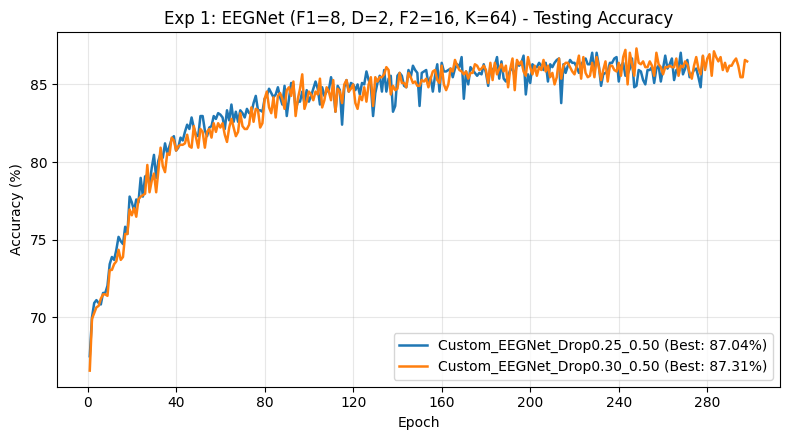

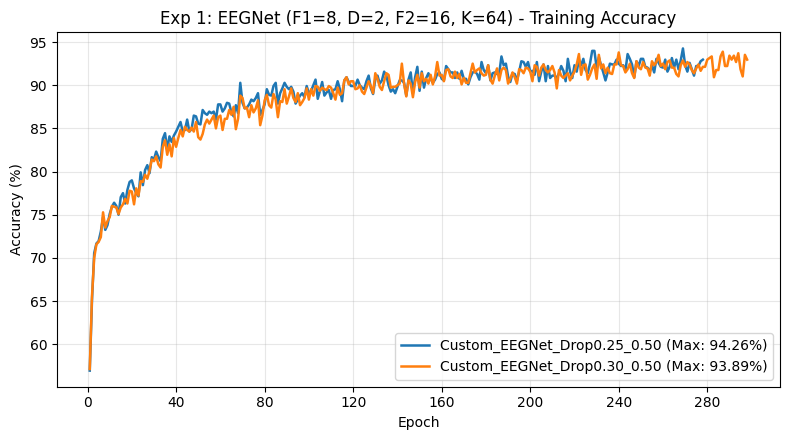

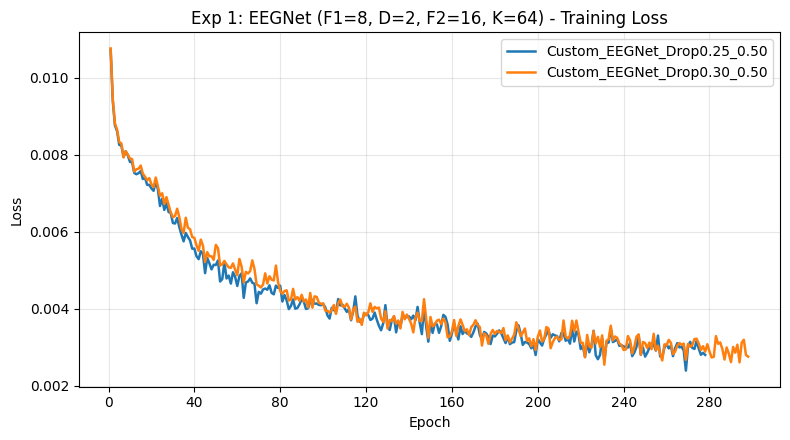

In [35]:
# =========================================================================
# EXP 1: Custom Compact EEGNet (F1=8, D=2, F2=16, kernel=64, drop=(0.25/0.30, 0.50), LeakyReLU(0.05))
# ADAM opt and CosineAnnealingLR
# =========================================================================
print("=== Experiment 1: Custom Compact EEGNet (F1=8, D=2, F2=16, kernel=64) ===")
exp_custom = [
    run_config(
        "Custom_EEGNet_Drop0.25_0.50", model_type='EEGNet', act='leaky_relu',
        negative_slope=0.05, F1=8, D=2, F2=16, kernel_length=64,
        dropout=(0.25, 0.50), lr=0.001, epochs=700, patience=50
    ),
    run_config(
        "Custom_EEGNet_Drop0.30_0.50", model_type='EEGNet', act='leaky_relu',
        negative_slope=0.05, F1=8, D=2, F2=16, kernel_length=64,
        dropout=(0.30, 0.50), lr=0.001, epochs=700, patience=50
    ),
]
plot_experiment_graphs(exp_custom, "Exp 1: EEGNet (F1=8, D=2, F2=16, K=64)")
all_summary.extend(exp_custom)



=== Experiment 1: Custom Compact EEGNet (F1=16, D=2, F2=32, kernel=51) ===


Custom_EEGNet_Drop0.25_0.50.pt:  64%|██████▍   | 450/700 [01:07<00:37,  6.69it/s, Train=98.3%, Test=85.4%, Best=86.20% (Ep 371), Patience=80/80]


Early stopping triggered at Epoch 451! Best Test Acc: 86.20% at Epoch 371.
--> [Custom_EEGNet_Drop0.25_0.50] Best Peak Test Acc: 86.20% (at Epoch 371/451)



Custom_EEGNet_Drop0.30_0.50.pt:  71%|███████▏  | 500/700 [01:14<00:29,  6.68it/s, Train=94.9%, Test=87.7%, Best=87.87% (Ep 421), Patience=80/80]


Early stopping triggered at Epoch 501! Best Test Acc: 87.87% at Epoch 421.
--> [Custom_EEGNet_Drop0.30_0.50] Best Peak Test Acc: 87.87% (at Epoch 421/501)



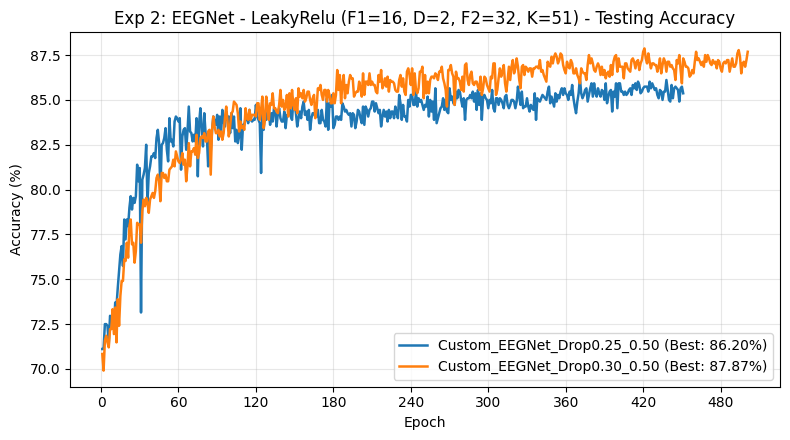

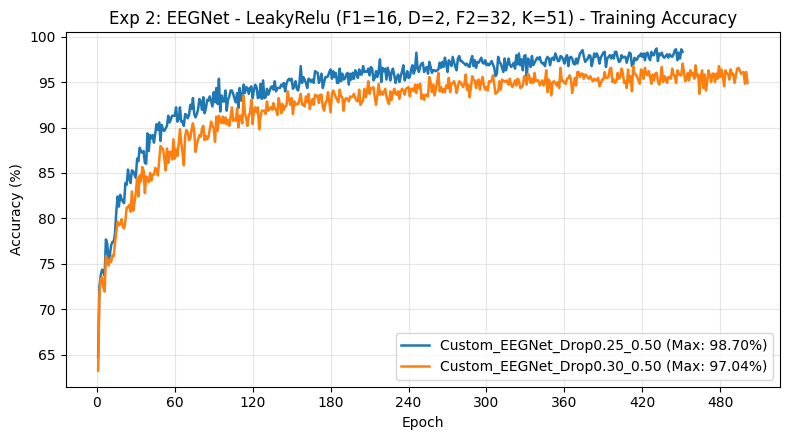

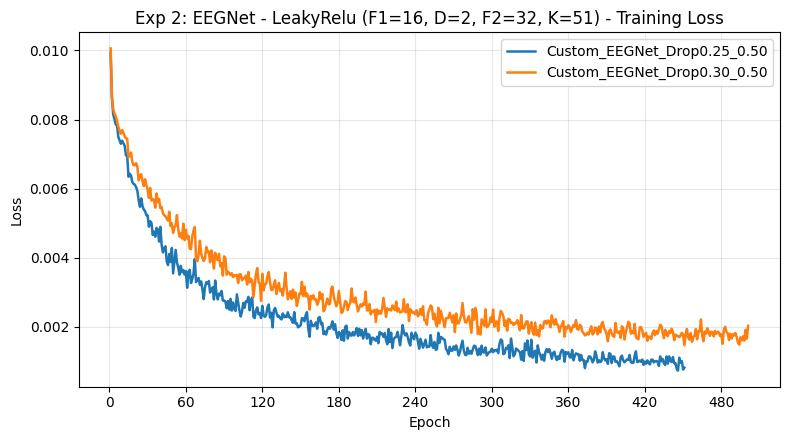

In [37]:
# =========================================================================
# EXP 2: Custom Compact EEGNet (F1=16, D=2, F2=32, kernel=51, drop=(0.25/0.50, 0.50), LeakyReLU(0.05))
# RMSprop opt and MultiStepLR
# =========================================================================
print("=== Experiment 2: Custom Compact EEGNet (F1=16, D=2, F2=32, kernel=51) ===")
exp_custom_2 = [
    run_config(
        "Custom_EEGNet_Drop0.25_0.50", model_type='EEGNet', act='leaky_relu',
        negative_slope=0.05, F1=16, D=2, F2=32, kernel_length=51,
        dropout=(0.25, 0.50), lr=0.001, epochs=700, patience=80
    ),
    run_config(
        "Custom_EEGNet_Drop0.50_0.50", model_type='EEGNet', act='leaky_relu',
        negative_slope=0.05, F1=16, D=2, F2=32, kernel_length=51,
        dropout=(0.50, 0.50), lr=0.001, epochs=700, patience=80
    ),
]
plot_experiment_graphs(exp_custom_2, "Exp 2: EEGNet - LeakyRelu (F1=16, D=2, F2=32, K=51)")
all_summary.extend(exp_custom_2)

=== Experiment 2: Custom Compact EEGNet (F1=25, D=2, F2=50, kernel=51) ===


Custom_EEGNet_Drop0.25_0.50.pt:  45%|████▌     | 317/700 [00:49<00:59,  6.40it/s, Train=93.0%, Test=83.7%, Best=84.72% (Ep 238), Patience=80/80]


Early stopping triggered at Epoch 318! Best Test Acc: 84.72% at Epoch 238.
--> [Custom_EEGNet_Drop0.25_0.50] Best Peak Test Acc: 84.72% (at Epoch 238/318)



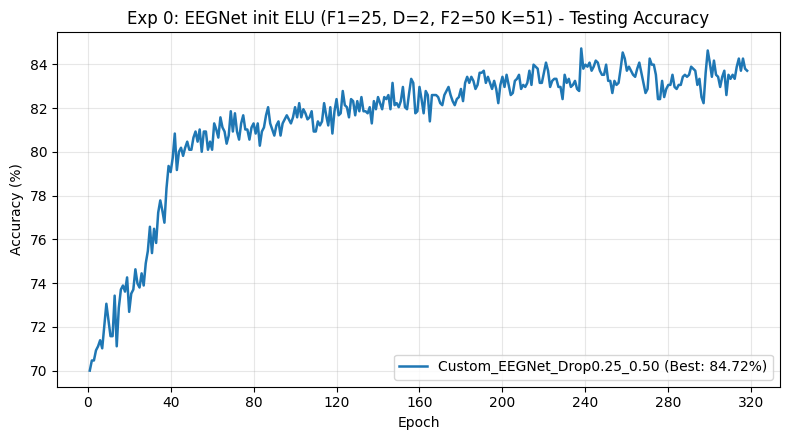

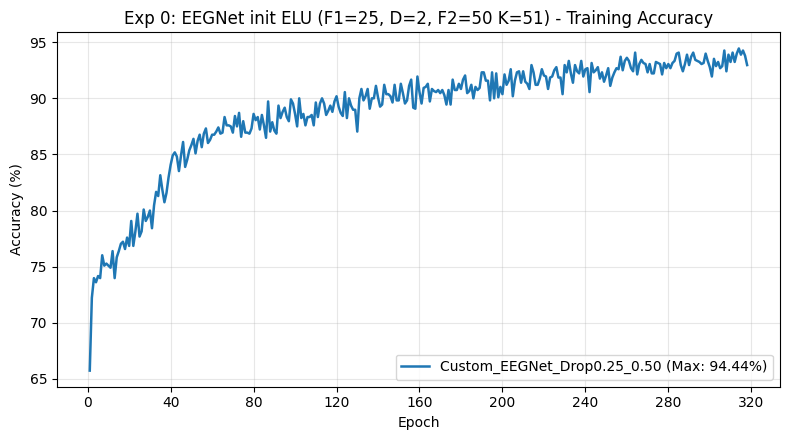

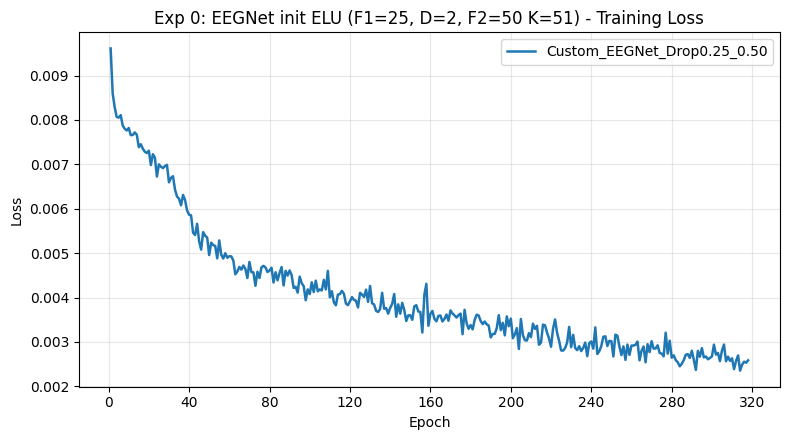

In [38]:
# =========================================================================
# EXP 0: Init EEGNet (F1=25, D=2, F2=50, kernel=51, drop=(0.50, 0.50), LeakyReLU(0.05))
# =========================================================================
print("=== Exp 0: EEGNet init ELU (F1=25, D=2, F2=50 K=51) ===")
exp_custom_0 = [
    run_config(
        "Custom_EEGNet_Drop0.25_0.50", model_type='EEGNet', act='elu',
        negative_slope=0.05, F1=16, D=2, F2=32, kernel_length=51,
        dropout=(0.50, 0.50), lr=0.001, epochs=700, patience=80
    ),
]
plot_experiment_graphs(exp_custom_0, "Exp 0: EEGNet init ELU (F1=25, D=2, F2=50 K=51)")
all_summary.extend(exp_custom_0)

=== Experiment 3: EEGNet EEGNet Different Combination ===


EEGNet_ELU.pt:  95%|█████████▍| 663/700 [01:33<00:05,  7.08it/s, Train=99.8%, Test=83.1%, Best=83.98% (Ep 464), Patience=200/200]


Early stopping triggered at Epoch 664! Best Test Acc: 83.98% at Epoch 464.
--> [EEGNet_ELU] Best Peak Test Acc: 83.98% (at Epoch 464/664)



EEGNet_ReLU.pt:  69%|██████▉   | 485/700 [01:07<00:29,  7.23it/s, Train=99.1%, Test=85.6%, Best=86.39% (Ep 286), Patience=200/200]


Early stopping triggered at Epoch 486! Best Test Acc: 86.39% at Epoch 286.
--> [EEGNet_ReLU] Best Peak Test Acc: 86.39% (at Epoch 286/486)



EEGNet_LeakyReLU_0.05.pt:  78%|███████▊  | 544/700 [01:15<00:21,  7.18it/s, Train=99.8%, Test=84.9%, Best=86.48% (Ep 345), Patience=200/200]


... (5 outputs left out)

EEGNet_ReLU_Drop0.1.pt: 100%|██████████| 700/700 [01:37<00:00,  7.21it/s, Train=99.8%, Test=83.9%, Best=85.09% (Ep 537), Patience=163/200]


--> [EEGNet_ReLU_Drop0.1] Best Peak Test Acc: 85.09% (at Epoch 537/700)



EEGNet_ReLU_Drop0.5.pt: 100%|██████████| 700/700 [01:36<00:00,  7.23it/s, Train=95.6%, Test=87.9%, Best=88.33% (Ep 594), Patience=106/200]


--> [EEGNet_ReLU_Drop0.5] Best Peak Test Acc: 88.33% (at Epoch 594/700)



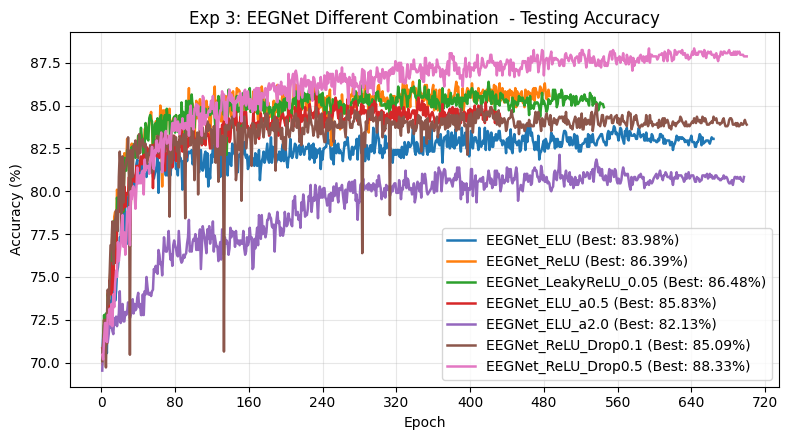

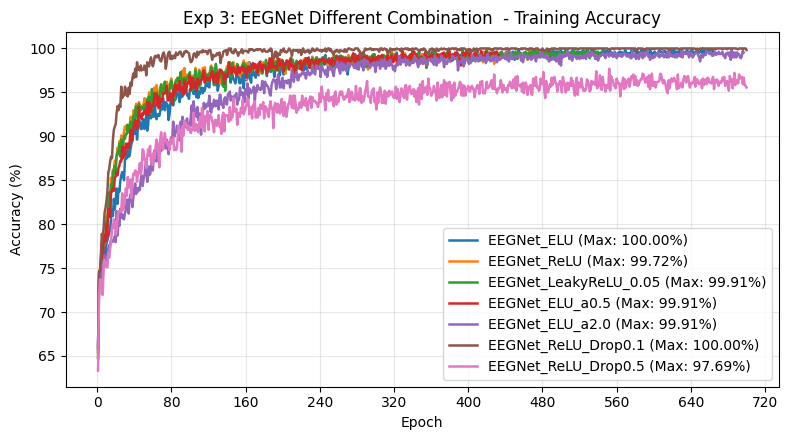

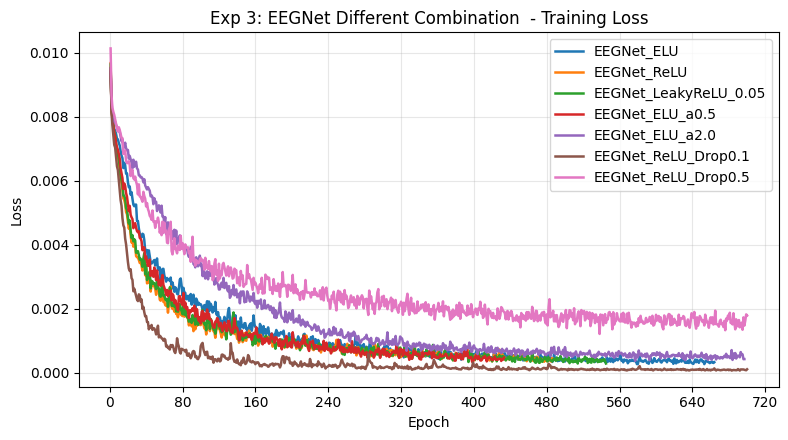

In [41]:
# =========================================================================
# EXP 3: Combination Functions on Standard EEGNet (F1=16, D=2, F2=32, K=51)
# =========================================================================
print("=== Experiment 3: EEGNet Different Combination ===")
exp_eegnet_act = [
    run_config("EEGNet_ELU", model_type='EEGNet', act='elu', dropout=0.25, lr=0.001, epochs=700, patience=200),
    run_config("EEGNet_ReLU", model_type='EEGNet', act='relu', dropout=0.25, lr=0.001, epochs=700, patience=200),
    run_config("EEGNet_LeakyReLU_0.05", model_type='EEGNet', act='leaky_relu', negative_slope=0.05, dropout=0.25, lr=0.001, epochs=700, patience=200),
    run_config("EEGNet_ELU_a0.5", model_type='EEGNet', act='elu', alpha=0.5, dropout=0.25, lr=0.001, epochs=700, patience=200),
    run_config("EEGNet_ELU_a2.0", model_type='EEGNet', act='elu', alpha=2.0, dropout=0.25, lr=0.001, epochs=700, patience=200),
    run_config("EEGNet_ReLU_Drop0.1", model_type='EEGNet', act='relu', dropout=0.1, lr=0.001, epochs=700, patience=200),
    run_config("EEGNet_ReLU_Drop0.5", model_type='EEGNet', act='relu', dropout=0.5, lr=0.001, epochs=700, patience=200),
]
plot_experiment_graphs(exp_eegnet_act, "Exp 3: EEGNet Different Combination ")
all_summary.extend(exp_eegnet_act)

=== Experiment 3: DeepConvNet Activation Functions ===


DeepConvNet_ELU.pt:  29%|██▊       | 858/3000 [03:07<07:47,  4.58it/s, Train=98.5%, Test=78.4%, Best=80.74% (Ep 359), Patience=500/500]


Early stopping triggered at Epoch 859! Best Test Acc: 80.74% at Epoch 359.
--> [DeepConvNet_ELU] Best Peak Test Acc: 80.74% (at Epoch 359/859)



DeepConvNet_ReLU.pt:  52%|█████▏    | 1568/3000 [05:42<05:12,  4.58it/s, Train=98.8%, Test=82.5%, Best=83.24% (Ep 1069), Patience=500/500]


Early stopping triggered at Epoch 1569! Best Test Acc: 83.24% at Epoch 1069.
--> [DeepConvNet_ReLU] Best Peak Test Acc: 83.24% (at Epoch 1069/1569)



DeepConvNet_LeakyReLU.pt:  31%|███       | 921/3000 [03:29<07:52,  4.40it/s, Train=98.6%, Test=82.2%, Best=83.15% (Ep 422), Patience=500/500]

Early stopping triggered at Epoch 922! Best Test Acc: 83.15% at Epoch 422.
--> [DeepConvNet_LeakyReLU] Best Peak Test Acc: 83.15% (at Epoch 422/922)



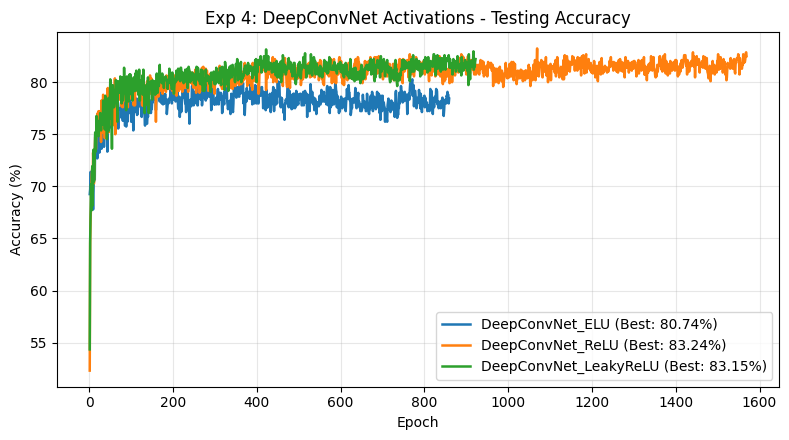

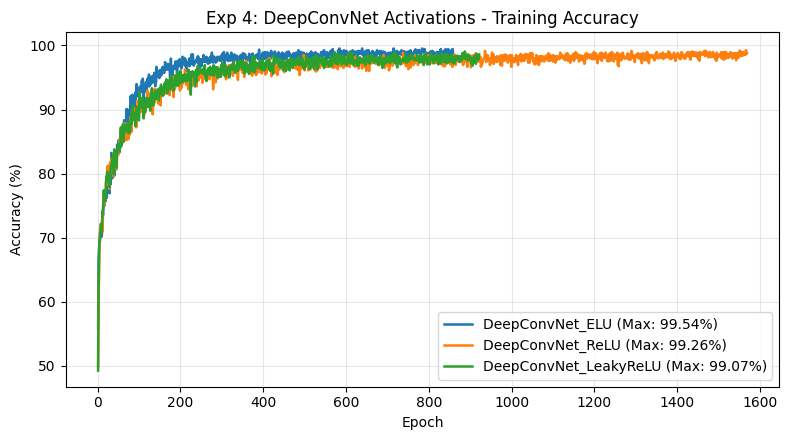

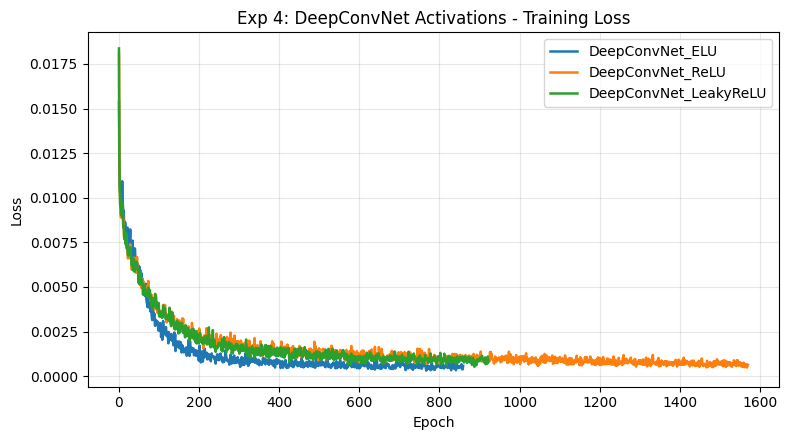

In [42]:

# =========================================================================
# EXP 4: Bonus DeepConvNet Activations
# =========================================================================
print("=== Experiment 3: DeepConvNet Activation Functions ===")
exp_deep_act = [
    run_config("DeepConvNet_ELU", model_type='DeepConvNet', act='elu', dropout=0.5, lr=0.001, epochs=3000, patience=500),
    run_config("DeepConvNet_ReLU", model_type='DeepConvNet', act='relu', dropout=0.5, lr=0.001, epochs=3000, patience=500),
    run_config("DeepConvNet_LeakyReLU", model_type='DeepConvNet', act='leaky_relu', negative_slope=0.05, dropout=0.5, lr=0.001, epochs=3000, patience=500),
]
plot_experiment_graphs(exp_deep_act, "Exp 4: DeepConvNet Activations")
all_summary.extend(exp_deep_act)

=== Experiment 5: DeepConvNet variation ===


DeepConvNet_ReLU_Drop0.25.pt:  43%|████▎     | 1287/3000 [04:40<06:13,  4.59it/s, Train=99.5%, Test=81.2%, Best=83.24% (Ep 868), Patience=420/420]


Early stopping triggered at Epoch 1288! Best Test Acc: 83.24% at Epoch 868.
--> [DeepConvNet_ReLU_Drop0.25] Best Peak Test Acc: 83.24% (at Epoch 868/1288)



DeepConvNet_ReLU_Drop0.50.pt:  22%|██▏       | 670/3000 [02:26<08:28,  4.58it/s, Train=97.1%, Test=80.1%, Best=82.13% (Ep 251), Patience=420/420]


Early stopping triggered at Epoch 671! Best Test Acc: 82.13% at Epoch 251.
--> [DeepConvNet_ReLU_Drop0.50] Best Peak Test Acc: 82.13% (at Epoch 251/671)



DeepConvNet_ReLU_Drop0.75.pt:  23%|██▎       | 703/3000 [02:33<08:20,  4.59it/s, Train=84.7%, Test=79.7%, Best=81.02% (Ep 284), Patience=420/420]


... (5 outputs left out)

DeepConvNet_ELU_a0.5.pt:  26%|██▌       | 772/3000 [02:49<08:09,  4.55it/s, Train=99.1%, Test=81.7%, Best=83.24% (Ep 353), Patience=420/420]


Early stopping triggered at Epoch 773! Best Test Acc: 83.24% at Epoch 353.
--> [DeepConvNet_ELU_a0.5] Best Peak Test Acc: 83.24% (at Epoch 353/773)



DeepConvNet_LeakyReLU_0.10.pt:  56%|█████▌    | 1675/3000 [06:05<04:49,  4.58it/s, Train=99.4%, Test=82.1%, Best=84.54% (Ep 1256), Patience=420/420]


Early stopping triggered at Epoch 1676! Best Test Acc: 84.54% at Epoch 1256.
--> [DeepConvNet_LeakyReLU_0.10] Best Peak Test Acc: 84.54% (at Epoch 1256/1676)



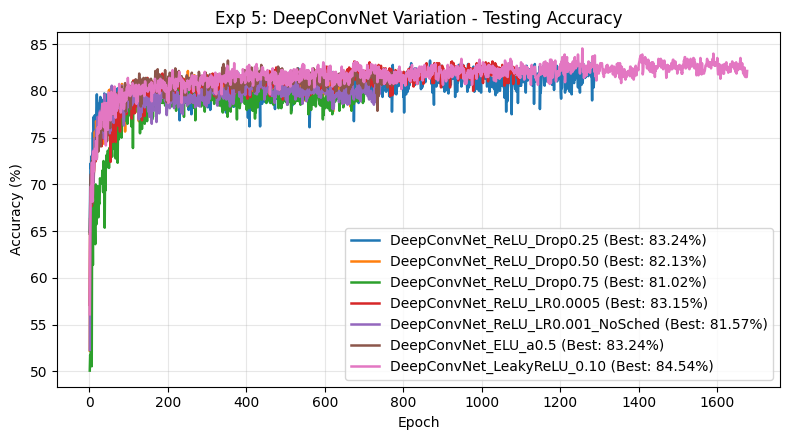

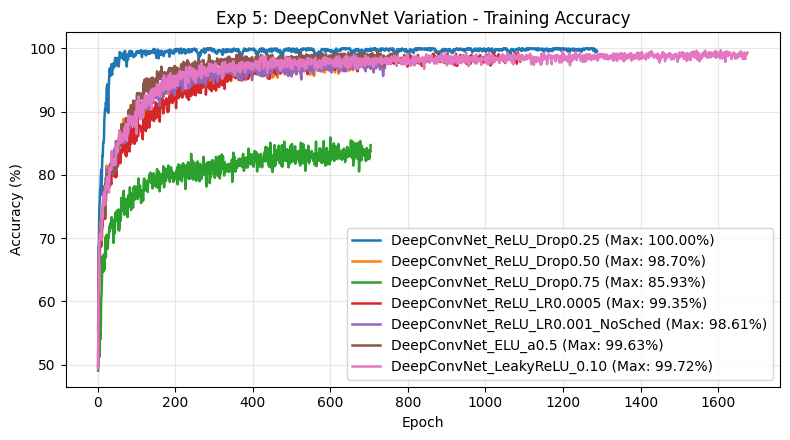

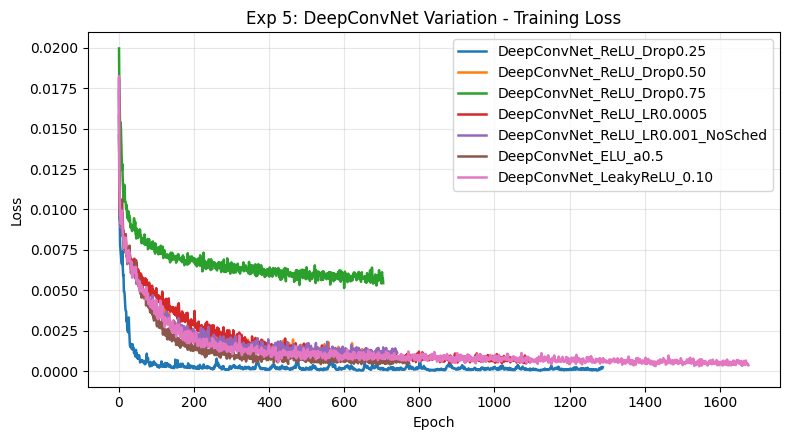

In [44]:
print("=== Experiment 5: DeepConvNet variation ===")
exp_deep_act_1 = [
    # =========================================================================
# EXP: DeepConvNet Dropout Variations (Baseline is 0.5)
# Rationale: With ~150k parameters, does a massive dropout of 0.7 prevent
# overfitting better, or does a light dropout of 0.25 learn faster?
# =========================================================================
    run_config("DeepConvNet_ReLU_Drop0.25", model_type='DeepConvNet', act='relu', dropout=0.25, lr=0.001, epochs=3000, patience=420),
    run_config("DeepConvNet_ReLU_Drop0.50", model_type='DeepConvNet', act='relu', dropout=0.50, lr=0.001, epochs=3000, patience=420),
    run_config("DeepConvNet_ReLU_Drop0.75", model_type='DeepConvNet', act='relu', dropout=0.75, lr=0.001, epochs=3000, patience=420),

# =========================================================================
# EXP: DeepConvNet Learning Rate & Scheduler Behavior
# Rationale: DeepConvNet can be unstable. Does a slower learning rate (0.0005)
# or a constant learning rate (use_sched=False) navigate the noise better?
# =========================================================================
    run_config("DeepConvNet_ReLU_LR0.0005", model_type='DeepConvNet', act='relu', dropout=0.5, lr=0.0005, epochs=3000, patience=420),
    run_config("DeepConvNet_ReLU_LR0.001_NoSched", model_type='DeepConvNet', act='relu', dropout=0.5, lr=0.001, epochs=3000, patience=420, use_sched=False),

# =========================================================================
# EXP: DeepConvNet Activation Fine-Tuning
# Rationale: Tweaking the negative slope of LeakyReLU or alpha of ELU
# to see how background EEG noise suppression affects the dense network.
# =========================================================================
    run_config("DeepConvNet_ELU_a0.5", model_type='DeepConvNet', act='elu', alpha=0.5, dropout=0.5, lr=0.001, epochs=3000, patience=420),
    run_config("DeepConvNet_LeakyReLU_0.10", model_type='DeepConvNet', act='leaky_relu', negative_slope=0.10, dropout=0.5, lr=0.001, epochs=3000, patience=420),
]
plot_experiment_graphs(exp_deep_act_1, "Exp 5: DeepConvNet Variation")
all_summary.extend(exp_deep_act_1)

In [45]:
# =========================================================================
# EXP 7: Ensemble of Best Checkpoints
# =========================================================================
top_models = sorted(all_summary, key=lambda x: x['best_test_acc'], reverse=True)[:3]
print(f"=== Experiment 6: Top-3 Checkpoint Ensemble ({[m['name'] for m in top_models]}) ===")
correct = 0
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        avg_probs = sum(torch.softmax(m['model_obj'](inputs), dim=1) for m in top_models) / len(top_models)
        preds = avg_probs.argmax(dim=1).cpu()
        correct += preds.eq(labels).sum().item()
ensemble_acc = round((correct / len(test_loader.dataset)) * 100, 2)
print(f"--> [Top-3 Ensemble] Official Test Accuracy: {ensemble_acc:.2f}%\n")

=== Experiment 6: Top-3 Checkpoint Ensemble (['EEGNet_ReLU_Drop0.5', 'Custom_EEGNet_Drop0.30_0.50', 'Custom_EEGNet_Drop0.30_0.50']) ===
--> [Top-3 Ensemble] Official Test Accuracy: 87.78%



In [46]:

# Summary Table
df_summary = pd.DataFrame([
    {
        'Experiment': r['name'], 'Model': r['model_type'], 'F1-D-F2': r['F1_D_F2'],
        'Kernel': r['kernel'], 'Act': r['act'], 'Dropout': r['dropout'],
        'Best Epoch': f"{r['best_epoch']}/{r['stopped_epoch']}",
        'Max Train Acc (%)': r['max_train_acc'], 'Peak Test Acc (%)': r['best_test_acc']
    } for r in all_summary
]).sort_values(by='Peak Test Acc (%)', ascending=False).reset_index(drop=True)

display(df_summary)

,Experiment,Model,F1-D-F2,Kernel,Act,Dropout,Best Epoch,Max Train Acc (%),Peak Test Acc (%)
0,EEGNet_ReLU_Drop0.5,EEGNet,16-2-32,51,relu,0.5,594/700,97.69,88.33
1,Custom_EEGNet_Drop0.30_0.50,EEGNet,16-2-32,51,leaky_relu,"(0.5, 0.5)",421/501,97.04,87.87
2,Custom_EEGNet_Drop0.30_0.50,EEGNet,8-2-16,64,leaky_relu,"(0.3, 0.5)",248/298,93.89,87.31
3,Custom_EEGNet_Drop0.30_0.50,EEGNet,16-2-32,51,leaky_relu,"(0.5, 0.5)",241/291,96.02,87.13
4,Custom_EEGNet_Drop0.25_0.50,EEGNet,8-2-16,64,leaky_relu,"(0.25, 0.5)",228/278,94.26,87.04
5,EEGNet_LeakyReLU_0.05,EEGNet,16-2-32,51,leaky_relu,0.25,345/545,99.91,86.48
6,EEGNet_ReLU,EEGNet,16-2-32,51,relu,0.25,286/486,99.72,86.39
7,Custom_EEGNet_Drop0.25_0.50,EEGNet,16-2-32,51,leaky_relu,"(0.25, 0.5)",371/451,98.70,86.20
8,EEGNet_ELU_a0.5,EEGNet,16-2-32,51,elu,0.25,233/433,99.91,85.83
9,Custom_EEGNet_Drop0.25_0.50,EEGNet,16-2-32,51,leaky_relu,"(0.25, 0.5)",177/227,97.22,85.19
